# Checking Candidates in Sentinel-2

So far I've only looked at the candidates in radar, which can be hard to read by eye. The USGS analysts confirmed each dredge in optical imagery taken within a day or two, so here I do the same with Sentinel-2. To be clear, this is just to check intuitions; none of it is an input anywhere. I want to see what dredges and the real false alarms look like in true color, what the moored dredges at site 0 look like, and whether some false alarms might be dredges the labelers missed.

Sentinel-2 photographs the same area every two to three days at 10m, and June & July are the dry season on the upper Madeira, so clear scenes should be pretty common. The catch is timing; dredges move, so an image from two days later might show no dredge because it left. For each candidate I find the clearest Sentinel-2 view as close as possible to its radar date, checking the cloud mask at the candidate itself rather than trusting the scene's overall cloud cover. Sentinel-1 passes at about 10am UTC and Sentinel-2 at about 14:40, so even same-day images are about 5 hours apart.

In [1]:
from concurrent.futures import ThreadPoolExecutor

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import rasterio
from rasterio.warp import transform as warp_points

from helpers import ORANGE, OUT, PROC, chip, db, load_points, scene

MAX_DAYS = 3  # the furthest from the radar date i'll accept an optical view
cands = gpd.read_file(PROC / "candidates.gpkg").to_crs("EPSG:4326")
cands["date"] = pd.to_datetime(cands["date"])

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
window = f"{cands['date'].min() - pd.Timedelta(days=MAX_DAYS):%Y-%m-%d}/{cands['date'].max() + pd.Timedelta(days=MAX_DAYS):%Y-%m-%d}"
items = {i.id: i for i in catalog.search(collections=["sentinel-2-l2a"], bbox=list(cands.total_bounds), datetime=window).items()}
print(f"{len(items)} Sentinel-2 tiles from {len({i.datetime.date() for i in items.values()})} dates")

# scene classes that rule a pixel out: no data (0, often outside the swath), saturated (1), cloud shadow (3),
# low-probability cloud (7), cloud (8, 9) and cirrus (10)
CLOUDY = {0, 1, 3, 7, 8, 9, 10}


def scl_at_candidates(item):
    """the scene class at each candidate inside this tile, for candidates within MAX_DAYS of it."""
    day = pd.Timestamp(item.datetime.date())
    near = cands[(cands["date"] - day).abs().dt.days <= MAX_DAYS]
    with rasterio.open(item.assets["SCL"].href) as src:
        xs, ys = warp_points("EPSG:4326", src.crs, near.geometry.x.tolist(), near.geometry.y.tolist())
        inside = [(i, x, y) for i, x, y in zip(near.index, xs, ys) if src.bounds.left < x < src.bounds.right and src.bounds.bottom < y < src.bounds.top]
        values = [v[0] for v in src.sample([(x, y) for _, x, y in inside])] if inside else []
    return [{"cand": i, "item": item.id, "s2_date": day, "clear": int(v) not in CLOUDY} for (i, _, _), v in zip(inside, values)]


with ThreadPoolExecutor(8) as pool:  # one remote read per tile; threads overlap the network waits
    looks = pd.DataFrame([r for rows in pool.map(scl_at_candidates, items.values()) for r in rows])
looks["days_off"] = (looks["s2_date"] - cands.loc[looks["cand"], "date"].values).dt.days

# per candidate: the clear view closest in time, preferring a later view on ties (dredges seen after, not before)
best = looks[looks["clear"]].assign(gap=lambda d: d["days_off"].abs()).sort_values(["gap", "days_off"], ascending=[True, False])
cands = cands.join(best.drop_duplicates("cand").set_index("cand")[["item", "days_off"]])

summary = cands.groupby("date").agg(
    candidates=("site", "size"), clear_same_day=("days_off", lambda d: (d == 0).sum()),
    clear_within_1_day=("days_off", lambda d: (d.abs() <= 1).sum()), clear_within_3_days=("days_off", lambda d: d.notna().sum()))
summary.index = summary.index.strftime("%b %d")
summary.loc["All"] = summary.sum()
summary

106 Sentinel-2 tiles from 17 dates


,candidates,clear_same_day,clear_within_1_day,clear_within_3_days
date,,,,
Jun 04,54,0,18,18
Jun 10,53,7,7,30
Jun 16,41,0,1,33
Jun 22,36,0,32,32
Jun 28,46,33,33,33
Jul 04,27,0,25,25
Jul 10,35,1,1,34
All,292,41,117,205


205 of the 292 candidates have a clear Sentinel-2 view within three days of their radar date, and 117 within one day; 41 have one on the same day. The scenes listed as cloud-free on June 10th and July 10th come from an orbit that only clips the edge of the reach, so most candidates fall outside them (no data, not cloud). June 4th is the main gap; its nearest clear scenes are cloudy or more than three days away for two-thirds of its candidates.

The cases I care most about are mostly covered. 26 of the 41 false alarms have a clear view within three days, 20 of them within one. Site 0 has 32 of 49 within three days but only 2 within one, which matters less there because its dredges are moored for weeks. Below are the chips themselves, starting with the 26 false alarms. Each pair shows the radar (VV, in dB) on the candidate's own date and the Sentinel-2 true color image from the nearest clear date, both about 600m across and centered on the candidate. True color comes from Sentinel-2's ready-made visual product, stretched per chip so the river isn't just dark. The title gives the gap between the two images in days, since a dredge seen in radar may have moved by the time of the optical image.

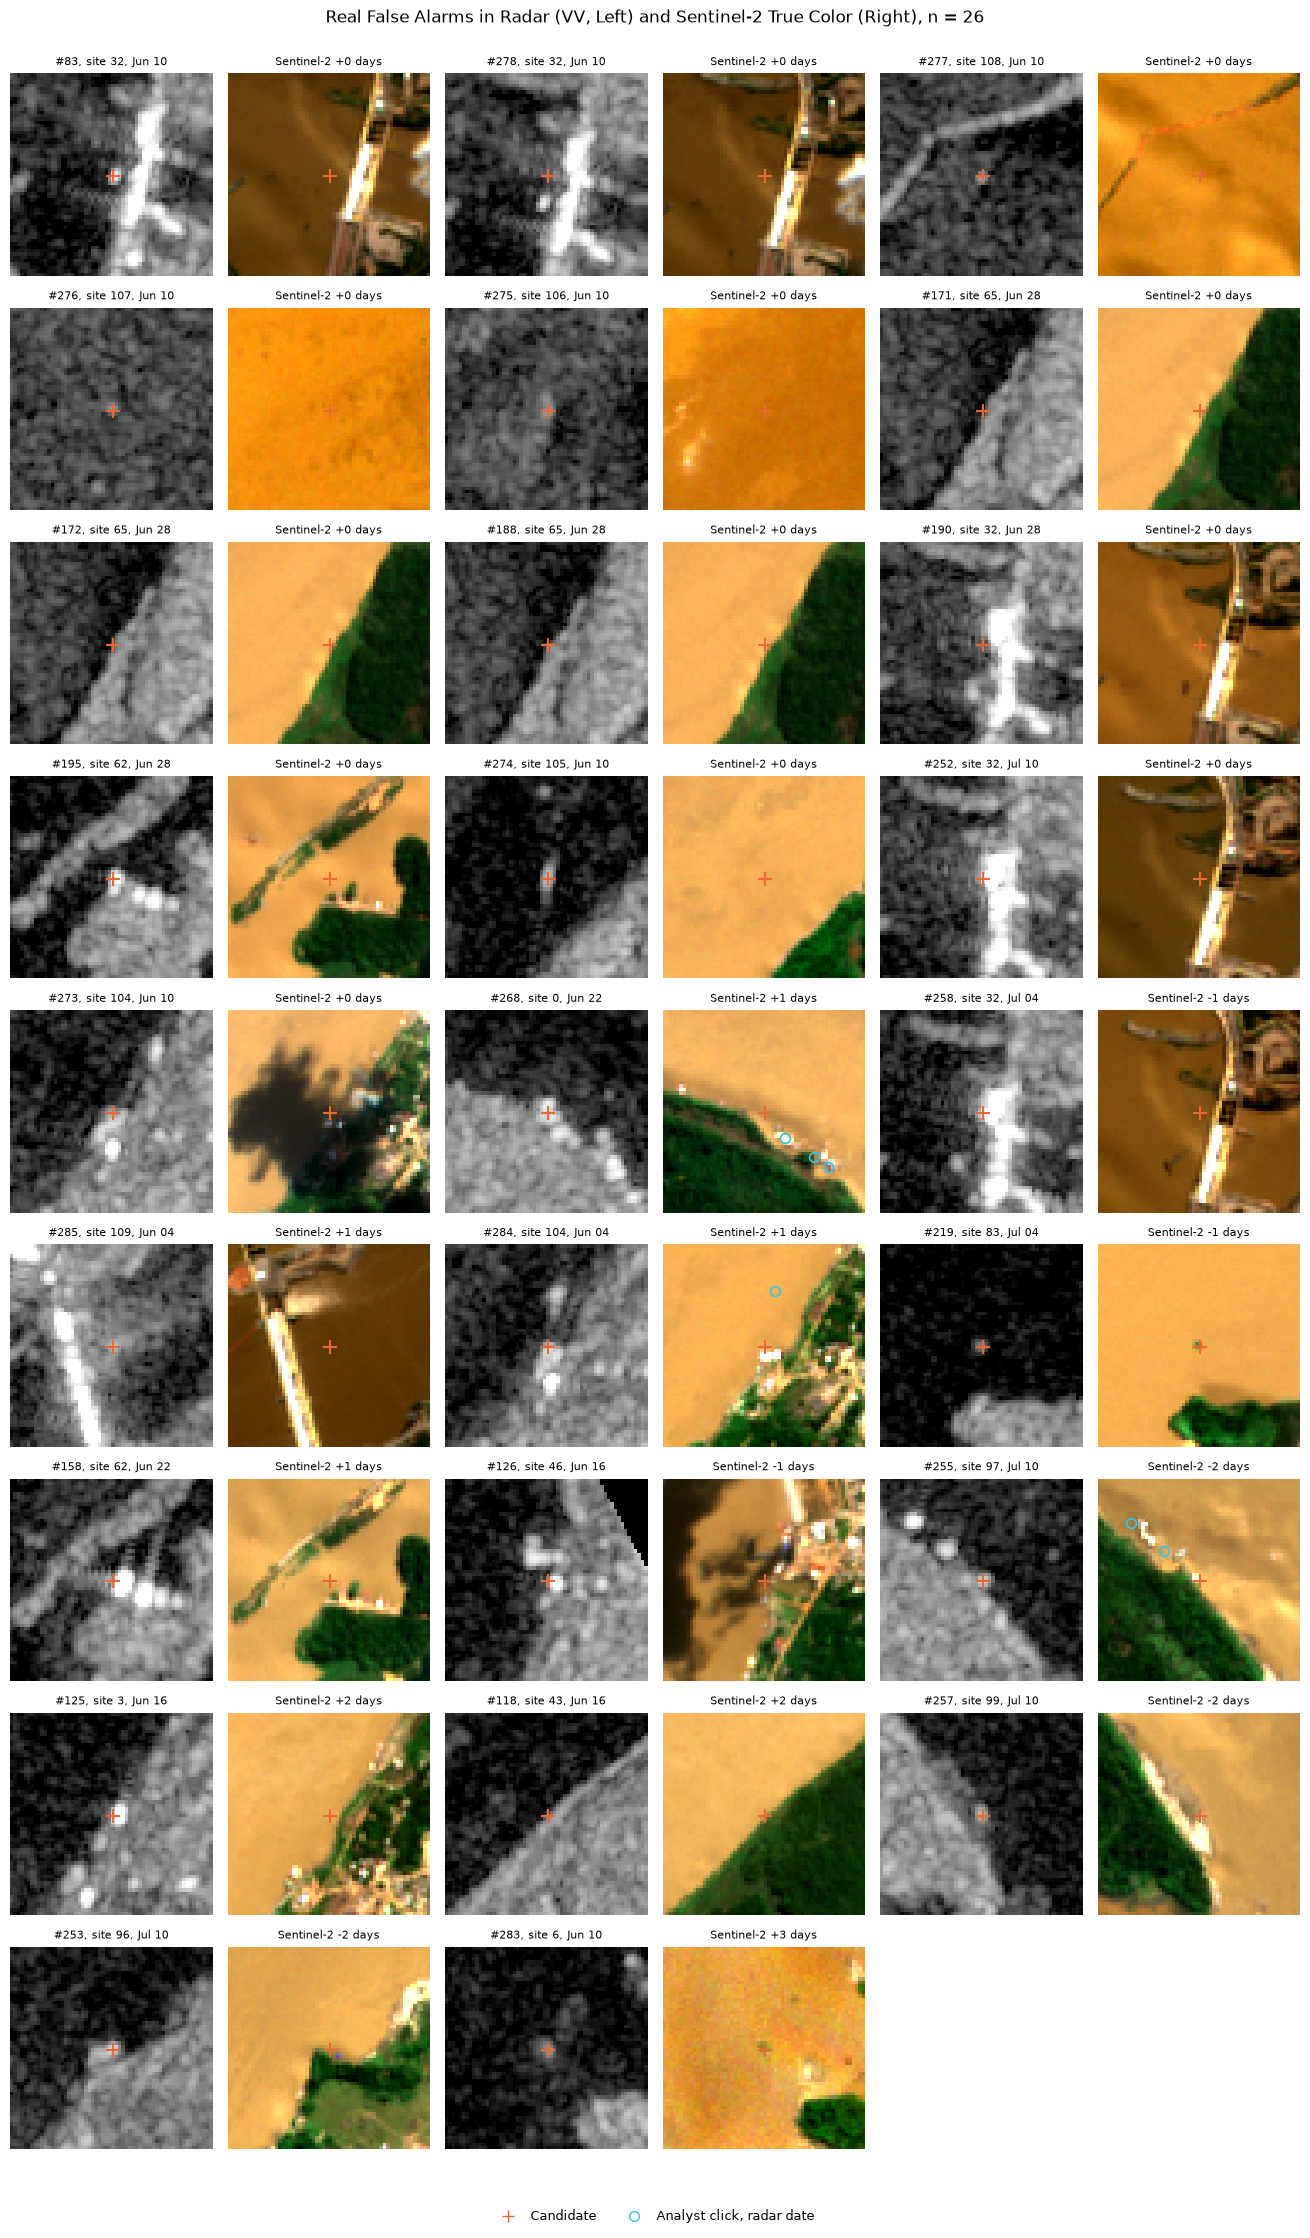

In [2]:
HALF, CYAN = 30, "#34c6eb"  # 30 px each side; both sensors have 10m pixels, so about 600m across
visual = load_points("Visual", crs="EPSG:4326")  # the analysts' clicks, to mark on the optical chips


def radar_chip(cand):
    with rasterio.open(scene(cand["date"])) as src:
        vv = chip(src, cand.geometry.x, cand.geometry.y, 2 * HALF, band=2)
    return db(np.where(vv > 1e30, 0, vv))


def optical_chip(cand):
    """a true color chip, plus where the analysts' clicks from the candidate's radar date fall in it (pixels)."""
    with rasterio.open(items[cand["item"]].assets["visual"].href) as src:
        (x,), (y,) = warp_points("EPSG:4326", src.crs, [cand.geometry.x], [cand.geometry.y])
        row, col = src.index(x, y)
        rgb = np.moveaxis(chip(src, x, y, 2 * HALF, band=[1, 2, 3]), 0, -1).astype(float)
        clicks = visual[visual["date"] == cand["date"]]
        # imshow puts pixel centers on whole numbers, hence the -0.5
        pts = [(c - (col - HALF) - 0.5, r - (row - HALF) - 0.5)
               for c, r in (~src.transform * xy for xy in zip(*warp_points("EPSG:4326", src.crs, clicks.geometry.x.tolist(), clicks.geometry.y.tolist())))]
    lo, hi = np.percentile(rgb, [2, 98])  # per-chip stretch so water and land both show
    return np.clip((rgb - lo) / max(hi - lo, 1), 0, 1), [(c, r) for c, r in pts if 0 <= c < 2 * HALF and 0 <= r < 2 * HALF]


def chip_grid(rows, title, path, per_row=3):
    """radar & optical pairs, three pairs to a row."""
    fig, axes = plt.subplots(int(np.ceil(len(rows) / per_row)), 2 * per_row, figsize=(4.4 * per_row, 2.4 * np.ceil(len(rows) / per_row)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, (i, cand) in enumerate(rows.iterrows()):
        ax_r, ax_o = axes[k // per_row, 2 * (k % per_row)], axes[k // per_row, 2 * (k % per_row) + 1]
        rgb, clicks = optical_chip(cand)
        ax_r.imshow(radar_chip(cand), cmap="gray", vmin=-25, vmax=5)
        ax_o.imshow(rgb)
        for c, r in clicks:
            ax_o.plot(c, r, "o", markersize=7, markerfacecolor="none", markeredgecolor=CYAN, markeredgewidth=1.2)
        for ax in (ax_r, ax_o):
            ax.plot(HALF, HALF, "+", color=ORANGE, markersize=10, markeredgewidth=1.5)
        ax_r.set_title(f"#{i}, site {cand['site']}, {cand['date']:%b %d}", fontsize=8)
        ax_o.set_title(f"Sentinel-2 {int(cand['days_off']):+d} days", fontsize=8)
    fig.suptitle(title, y=1.0)
    fig.legend(handles=[plt.Line2D([], [], ls="", marker="+", color=ORANGE, markersize=9, label="Candidate"),
                        plt.Line2D([], [], ls="", marker="o", markerfacecolor="none", markeredgecolor=CYAN, markersize=7, label="Analyst click, radar date")],
               loc="lower center", bbox_to_anchor=(0.5, -0.03), ncol=2, fontsize=9, frameon=False)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()


false_alarms = cands[(cands["dredge"] == 0) & cands["days_off"].notna()].sort_values("days_off", key=abs)
chip_grid(false_alarms, f"Real False Alarms in Radar (VV, Left) and Sentinel-2 True Color (Right), n = {len(false_alarms)}", OUT / "02_2_false_alarms_s2.png")

Most false alarms turn out to be fixed objects, which are much more obvious in the RGB imagery than in the radar. Going through the 26 by eye, they fall into a few groups:
- **The Santo Antônio dam (6).** Sites 32 and 109 sit at about 63.95°W, 8.80°S, which matches the dam just upstream of Porto Velho. In true color it's a long concrete structure across the river, and in radar it's one of the brightest things in the scene, so the detectors fire on it every date. Manmade structures in general can look like dredges to the detectors.
- **The Porto Velho waterfront (4).** Sites 3, 46 and 104 are along the city's riverbank, where Sentinel-2 shows roofs, docks and a port.
- **Plain banks or sandbars (6).** Sites 43, 65, 97 and 99 are the edge of forest or a bright sand beach with nothing on it.
- **Open water with nothing in either image (5).** Four of these are Global-only detections from June 10th (sites 105 to 108), and they're readable in the USGS file, so they aren't from the corrupt tiles. One (#274) shows a small bright streak in radar and nothing five hours later, which might be a boat that moved.
- **Small objects that might be boats or unlabeled dredges (5).** Sites 0, 62, 83 and 96 show small bright or colored objects near the candidate, some along the bank next to labeled dredges. I can't tell a dredge from another boat at 10m, but some of these "false alarms" may be dredges the labels missed.

This points to a simple fix the models can't learn from 41 examples: mask known infrastructure. The dam and the city waterfront are already mapped (in OpenStreetMap, for example), and excluding them would remove about a third of these false alarms before running any model.

For comparison, here are the labeled dredges. First site 0, the group of dredges moored against the bank that every model struggles with. Its candidates overlap heavily, so I show one per date, the one with the closest clear view. Then nine dredges in open water (no land within the 200m the bank distance looks at), picked at random among those with a clear view within a day, to see what a typical dredge looks like in true color.

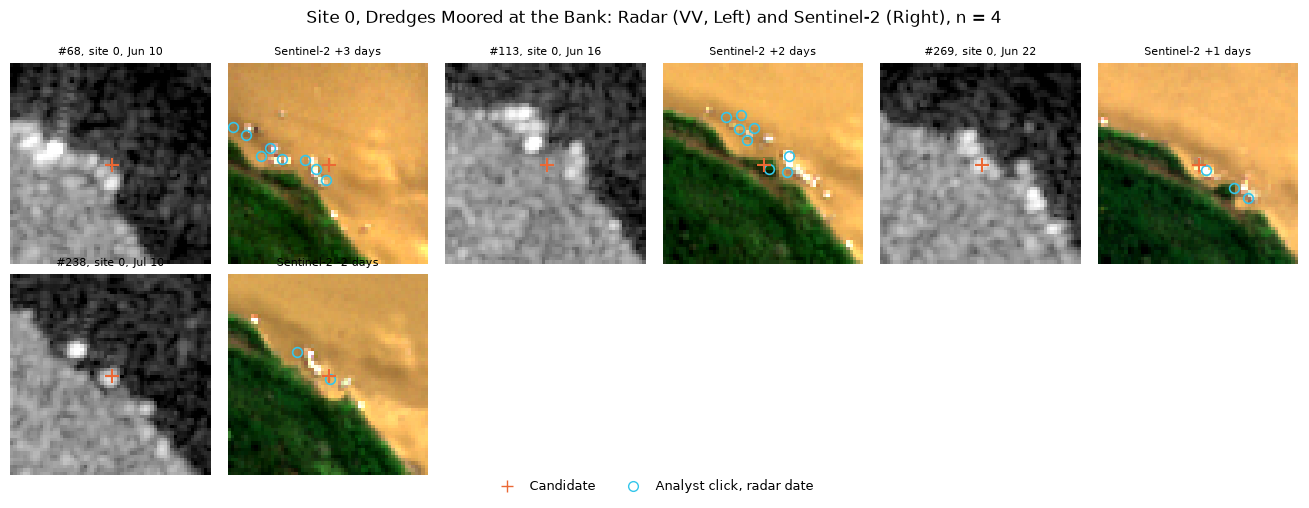

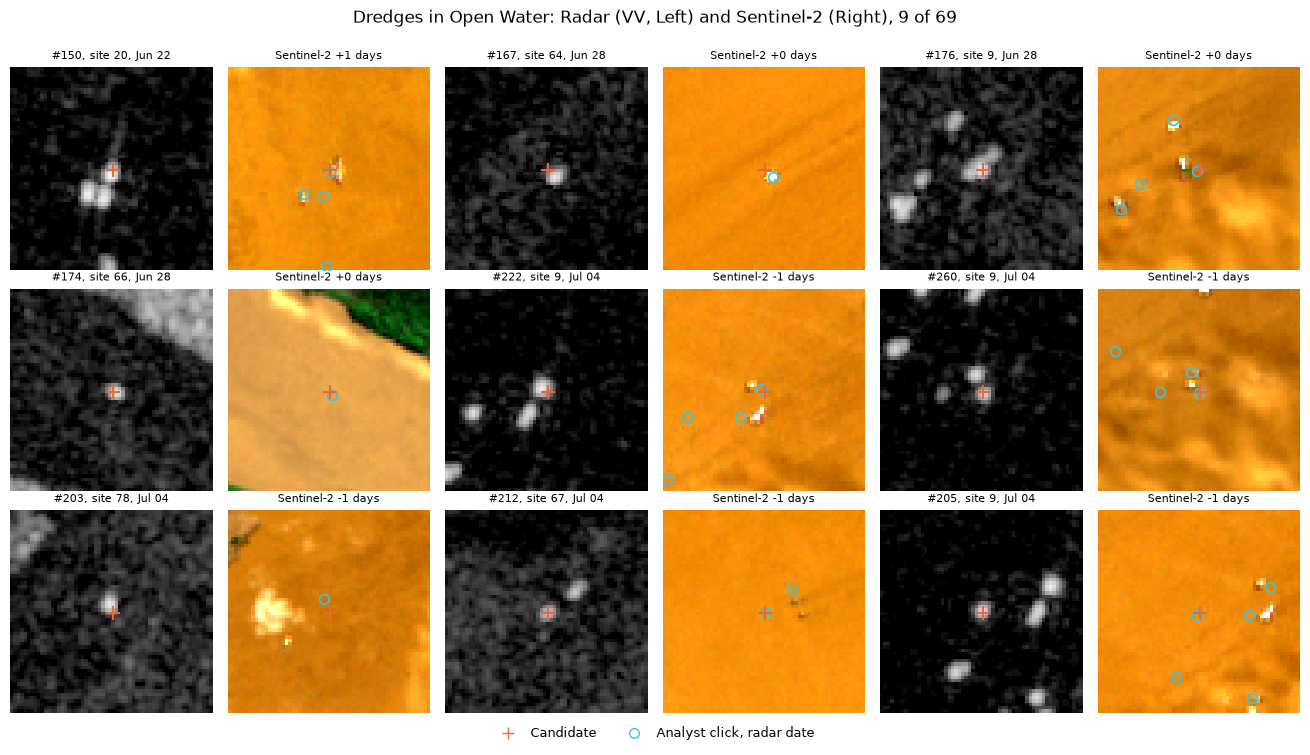

In [3]:
# site 0: one candidate per radar date, the one with the closest clear optical view
site0 = (cands[(cands["site"] == 0) & (cands["dredge"] == 1) & cands["days_off"].notna()]
         .sort_values("days_off", key=abs).drop_duplicates("date").sort_values("date"))
chip_grid(site0, f"Site 0, Dredges Moored at the Bank: Radar (VV, Left) and Sentinel-2 (Right), n = {len(site0)}", OUT / "02_2_site0_s2.png")

# open water: no land within the 200m bank-distance window, optical view within a day
open_water = cands[(cands["dredge"] == 1) & (cands["dist_bank_m"] >= 200) & (cands["days_off"].abs() <= 1)]
chip_grid(open_water.sample(9, random_state=1).sort_values("date"),
          f"Dredges in Open Water: Radar (VV, Left) and Sentinel-2 (Right), 9 of {len(open_water)}", OUT / "02_2_open_water_dredges_s2.png")